**Eye-Tracking & Neurocognitive Intelligence | Eye-Movement Modelling & Advanced AI | Presented by: Reza Saadatyar (2026)**

**02 | Statistical Baselines and Classical Machine Learning**

![Original GazeBase feature inputs, four classical model results and independent-person Validation](../../images/02_statistical_and_classical_ml.svg)

**Objective:** Compare a no-signal class-prior baseline with Logistic Regression, Random Forest and Gradient Boosting for **four-class GazeBase recording-task identity** (FXS, HSS, RAN, TEX). These are source protocols, not cognitive or clinical labels.

**Experimental unit:** One original recording is one classification observation; the independent split unit is a **participant**. Notebook 01 selected 10 people and 40 task recordings. The current run fits on **24 Train records from 6 people** and evaluates all four fixed candidates on **8 Validation records from 2 different people**.

**Recorded Validation evidence:** The class-prior baseline scored **Accuracy 0.25, Macro F1 0.10 and Balanced Accuracy 0.25**; Logistic Regression, Random Forest and Gradient Boosting each scored **1.00 on all three metrics** and classified all eight Validation records correctly. These are small-cohort **development results**, not unseen-population accuracy estimates or final Test results.

**Scientific boundary:** Train-only imputation and applicable scaling are fitted within the stored pipelines. Model inputs exclude participant/task identifiers and record duration. Different task stimuli, measurement conditions and anomalous motion measurements may make protocol identification easier without establishing generalisable eye-movement understanding. No Test results are inspected in this notebook.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_movement_modelling")

# ---------------------------- 2. Data and Models -----------------------------
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from IPython.display import display

# ------------------------ 3. Research Infrastructure -------------------------
from core.stage_outputs import ensure_stage_inputs
from core.output_download import download_outputs_from_colab
from core.plot_style import plot_style, save_figure
from s2_data import TASKS, CLASS_TO_INDEX, load_protocol
from s2_classical import classical_candidates
from s2_metrics import (
    FEATURE_COLUMN_NAMES, require_split_consistency,
    classical_record_predictions, metric_row,
)

# ----------------------------- 4. Output Context -----------------------------
output_dir = root / "eye_movement_modelling" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Current study outputs:", output_dir)

Repository updated.
Current study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output


**02. Recover and Check Notebook 01 Feature Inputs**

Restore the named current Notebook 01 files where needed: `01_record_features.csv`, `01_split_assignments.csv` and `01_protocol.csv`. Source record IDs, task labels and participant assignments are checked for consistency before fitting.

The saved run reports **24 Train recordings from 6 people**, **8 Validation recordings from 2 people** and nine engineered gaze-feature columns. The complete source registry also contains the pilot Test rows for alignment checks, but **Test records are excluded from model fitting, imputation/scaling, Validation scoring and selection**. This distinction is important: reading a registry is not the same as using Test results to optimise a model.


In [ ]:
# ======================== 02. Recover Record Features ========================

# ----------------------- 1. Named Current Input Files ------------------------
ensure_stage_inputs(
    output_dir, 1,
    ("01_record_features.csv", "01_split_assignments.csv",
     "01_protocol.csv"),
)
features = pd.read_csv(
    output_dir / "01_record_features.csv",
    dtype={"participant_id": str, "record_id": str},
)
split = pd.read_csv(
    output_dir / "01_split_assignments.csv",
    dtype={"participant_id": str, "record_id": str},
)
protocol = load_protocol(output_dir / "01_protocol.csv")
require_split_consistency(features, split)

# --------------------- 2. Separate Train and Validation ----------------------
train = features.loc[features.split.eq("train")].copy()
validation = features.loc[features.split.eq("validation")].copy()
feature_names = list(FEATURE_COLUMN_NAMES)
if train.empty or validation.empty:
    raise ValueError("No Train/Validation task records were selected")
print("Protocol purpose:", protocol["purpose"])
print("Train records / participants:", len(train),
      train.participant_id.nunique())
print("Validation records / participants:", len(validation),
      validation.participant_id.nunique())
print("Input feature columns:", feature_names)
display(train[["record_id", "task", "valid_fraction"]].head(8))
candidates = classical_candidates(seed=protocol["split_seed"])
reported = []


Protocol purpose: pilot
Train records / participants: 24 6
Validation records / participants: 8 2
Input feature columns: ['valid_fraction', 'x_sd_dva', 'y_sd_dva', 'step_median_dva', 'step_p95_dva', 'speed_median_dva_s', 'speed_p95_dva_s', 'pupil_coverage', 'pupil_median_uncalibrated']


,record_id,task,valid_fraction
8,S_1003_S1_FXS,FXS,0.986599
9,S_1003_S1_HSS,HSS,0.997424
10,S_1003_S1_RAN,RAN,0.991051
11,S_1003_S1_TEX,TEX,0.990009
12,S_1004_S1_FXS,FXS,0.963606
13,S_1004_S1_HSS,HSS,0.822140
14,S_1004_S1_RAN,RAN,0.976138
15,S_1004_S1_TEX,TEX,0.817411


**03. Prior-Only Baseline**

The fitted `DummyClassifier(strategy="prior")` predicts the training-derived class distribution without learning gaze-to-task associations. With four equally represented source tasks in Train, its recorded Validation class prediction is always **FXS**.

On the **8 Validation records**, it correctly identifies the **2 FXS recordings** and misclassifies the other 6: **Accuracy 0.25, Macro F1 0.10, Balanced Accuracy 0.25**. Macro F1 is lower than Accuracy because only one class receives a positive prediction. This baseline does not provide evidence that the gaze features carry task information.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
0,class_prior,validation,8,2,0.25,0.1,0.25


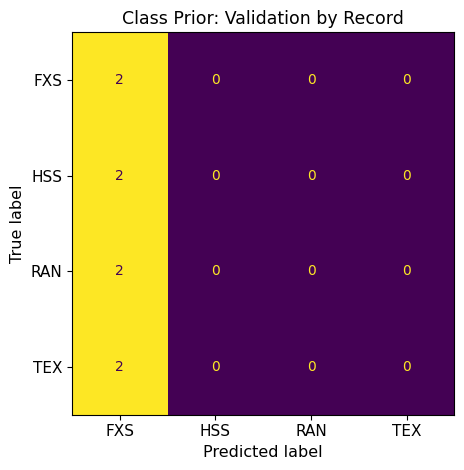

In [ ]:
# ==================== 03. No-Signal Class-Prior Baseline =====================

# --------------------------- 1. Fit Train Records ----------------------------
name = "class_prior"
model = candidates[name]
model.fit(train[feature_names], train["task"].map(CLASS_TO_INDEX))
joblib.dump(model, output_dir / f"02_{name}.joblib")

# ---------------------- 2. Evaluate Held-Out Validation ----------------------
pred = classical_record_predictions(
    model, validation, model_name=name, partition="validation",
)
pred.to_csv(output_dir / f"02_{name}_validation_predictions.csv", index=False)
row = metric_row(
    pred.target_index, pred.pred_index, model=name,
    partition="validation",
    n_participants=validation["participant_id"].nunique(),
)
reported.append(row)
display(pd.DataFrame([row]))

# ---------------------- 3. Display Model Error Pattern -----------------------
matrix = confusion_matrix(
    pred.target_index, pred.pred_index, labels=range(len(TASKS)),
)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=ax, colorbar=False, values_format="d",
)
ax.set_title("Class Prior: Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"02_{name}_confusion.png")
plt.show()


**04. Logistic Regression**

The fixed class-balanced Logistic Regression Pipeline uses Train-only median imputation and `StandardScaler`. Its recorded confusion matrix is diagonal, with **2/2 Validation recordings correctly identified in each of FXS, HSS, RAN and TEX**.

Recorded **Accuracy = Macro F1 = Balanced Accuracy = 1.00** (8/8 records; 2 people). This demonstrates separation within the specified pilot Validation subset, not guaranteed performance for new participants, sessions, devices or stimuli. Coefficients should not be interpreted causally given the small cohort and potentially correlated engineered features.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
0,logistic_regression,validation,8,2,1.0,1.0,1.0


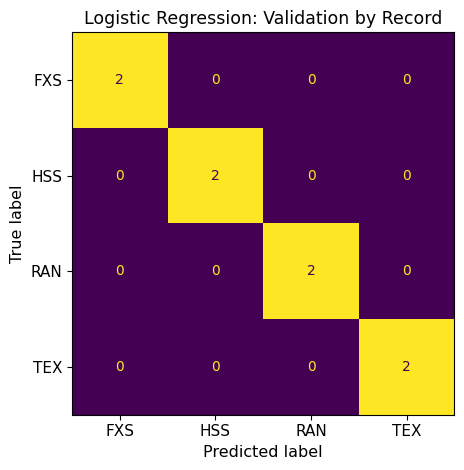

In [ ]:
# ======================= 04. Logistic Regression Model =======================

# --------------------------- 1. Fit Train Records ----------------------------
name = "logistic_regression"
model = candidates[name]
model.fit(train[feature_names], train["task"].map(CLASS_TO_INDEX))
joblib.dump(model, output_dir / f"02_{name}.joblib")

# ---------------------- 2. Evaluate Held-Out Validation ----------------------
pred = classical_record_predictions(
    model, validation, model_name=name, partition="validation",
)
pred.to_csv(output_dir / f"02_{name}_validation_predictions.csv", index=False)
row = metric_row(
    pred.target_index, pred.pred_index, model=name,
    partition="validation",
    n_participants=validation["participant_id"].nunique(),
)
reported.append(row)
display(pd.DataFrame([row]))

# ---------------------- 3. Display Model Error Pattern -----------------------
matrix = confusion_matrix(
    pred.target_index, pred.pred_index, labels=range(len(TASKS)),
)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=ax, colorbar=False, values_format="d",
)
ax.set_title("Logistic Regression: Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"02_{name}_confusion.png")
plt.show()


**05. Random Forest**

The fitted Random Forest uses 120 trees, maximum depth 8, minimum leaf size 2, class balancing and Train-only median imputation. The recorded Validation confusion matrix is diagonal: **8/8 correct across four classes**.

Recorded **Accuracy = Macro F1 = Balanced Accuracy = 1.00**, on the same **2 Validation participants** as the other models. The result is a tie with Logistic Regression, not evidence that the nonlinear ensemble is superior. Feature importance, if examined later, would describe predictive association rather than physiological causation.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
0,random_forest,validation,8,2,1.0,1.0,1.0


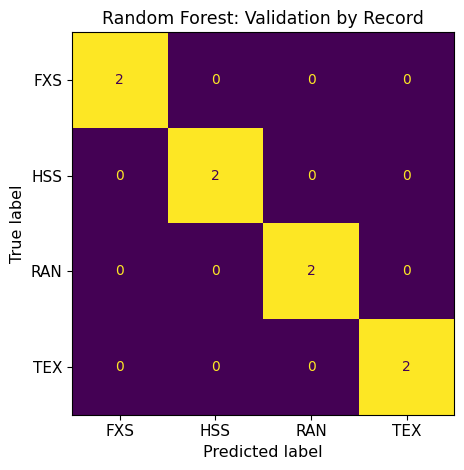

In [ ]:
# ========================== 05. Random Forest Model ==========================

# --------------------------- 1. Fit Train Records ----------------------------
name = "random_forest"
model = candidates[name]
model.fit(train[feature_names], train["task"].map(CLASS_TO_INDEX))
joblib.dump(model, output_dir / f"02_{name}.joblib")

# ---------------------- 2. Evaluate Held-Out Validation ----------------------
pred = classical_record_predictions(
    model, validation, model_name=name, partition="validation",
)
pred.to_csv(output_dir / f"02_{name}_validation_predictions.csv", index=False)
row = metric_row(
    pred.target_index, pred.pred_index, model=name,
    partition="validation",
    n_participants=validation["participant_id"].nunique(),
)
reported.append(row)
display(pd.DataFrame([row]))

# ---------------------- 3. Display Model Error Pattern -----------------------
matrix = confusion_matrix(
    pred.target_index, pred.pred_index, labels=range(len(TASKS)),
)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=ax, colorbar=False, values_format="d",
)
ax.set_title("Random Forest: Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"02_{name}_confusion.png")
plt.show()


**06. Gradient Boosting**

The fixed Histogram Gradient Boosting Pipeline uses 65 boosting iterations, constrained leaf complexity and Train-only median imputation. Its recorded confusion matrix also shows **2/2 correct recordings per class**, with **Accuracy = Macro F1 = Balanced Accuracy = 1.00**.

This is the same eight-record Validation subset, not an independent replication. The small **24-record Training set** limits conclusions about stability, and a perfect pilot score must not motivate model changes using Test results.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
0,gradient_boosting,validation,8,2,1.0,1.0,1.0


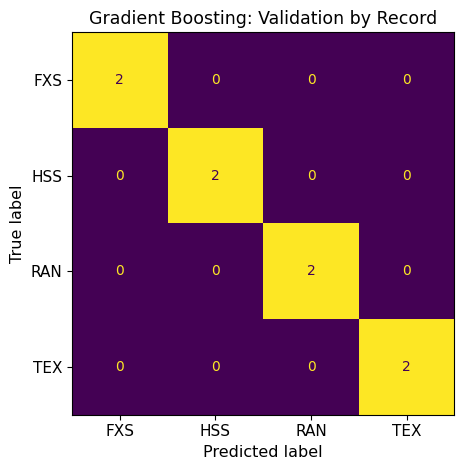

In [ ]:
# ======================== 06. Gradient Boosting Model ========================

# --------------------------- 1. Fit Train Records ----------------------------
name = "gradient_boosting"
model = candidates[name]
model.fit(train[feature_names], train["task"].map(CLASS_TO_INDEX))
joblib.dump(model, output_dir / f"02_{name}.joblib")

# ---------------------- 2. Evaluate Held-Out Validation ----------------------
pred = classical_record_predictions(
    model, validation, model_name=name, partition="validation",
)
pred.to_csv(output_dir / f"02_{name}_validation_predictions.csv", index=False)
row = metric_row(
    pred.target_index, pred.pred_index, model=name,
    partition="validation",
    n_participants=validation["participant_id"].nunique(),
)
reported.append(row)
display(pd.DataFrame([row]))

# ---------------------- 3. Display Model Error Pattern -----------------------
matrix = confusion_matrix(
    pred.target_index, pred.pred_index, labels=range(len(TASKS)),
)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=ax, colorbar=False, values_format="d",
)
ax.set_title("Gradient Boosting: Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"02_{name}_confusion.png")
plt.show()


**07. Compare Models on the Same Validation Records**

All four candidates were evaluated on the **same 8 source recordings from 2 independent participants**, using one prediction per recording and the fixed FXS/HSS/RAN/TEX label order. The recorded Validation comparison is:

| Model | Accuracy | Macro F1 | Balanced Accuracy |
| --- | ---: | ---: | ---: |
| Class prior | 0.25 | 0.10 | 0.25 |
| Logistic Regression | 1.00 | 1.00 | 1.00 |
| Random Forest | 1.00 | 1.00 | 1.00 |
| Gradient Boosting | 1.00 | 1.00 | 1.00 |

The three fitted gaze-feature models tie on the reported metrics. The comparison establishes **pilot Validation discrimination of source recording tasks**, not model superiority, external generalisation or neurocognitive prediction. Notebook 05 applies the predefined Validation selection rule after the remaining temporal candidates have been evaluated; no Test-based choice is made here.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
3,gradient_boosting,validation,8,2,1.00,1.0,1.00
1,logistic_regression,validation,8,2,1.00,1.0,1.00
2,random_forest,validation,8,2,1.00,1.0,1.00
0,class_prior,validation,8,2,0.25,0.1,0.25


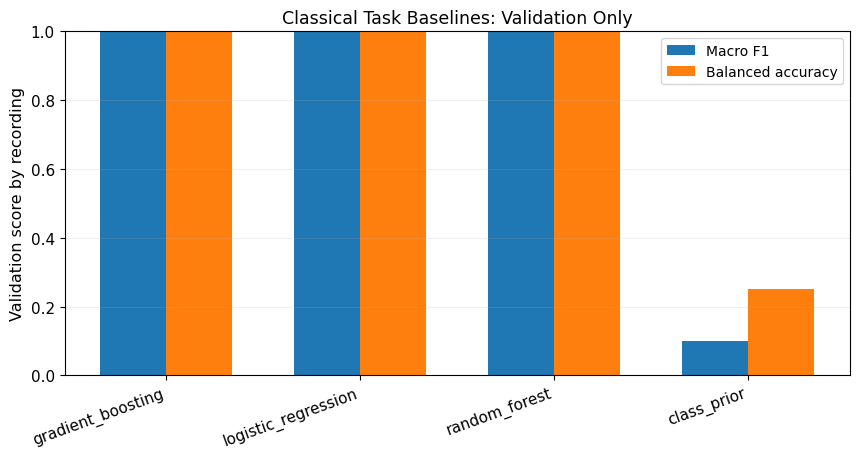

In [ ]:
# ===================== 07. Compare Classical Validation ======================

# ----------------------- 1. Persist Comparable Scores ------------------------
metrics = pd.DataFrame(reported).sort_values(
    ["macro_f1", "balanced_accuracy", "model"],
    ascending=[False, False, True],
)
metrics.to_csv(output_dir / "02_validation_metrics.csv", index=False)
display(metrics)

# ------------------------ 2. Plot Record-Level Scores ------------------------
fig, ax = plt.subplots(figsize=(8.7, 4.7))
positions = np.arange(len(metrics))
ax.bar(positions - 0.17, metrics["macro_f1"], width=0.34,
       label="Macro F1")
ax.bar(positions + 0.17, metrics["balanced_accuracy"], width=0.34,
       label="Balanced accuracy")
ax.set_xticks(positions, metrics["model"], rotation=20, ha="right")
ax.set(ylabel="Validation score by recording",
       ylim=(0, 1), title="Classical Task Baselines: Validation Only")
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
save_figure(fig, output_dir / "02_classical_comparison.png")
plt.show()


**08. Scientific Interpretation and Local Output Package**

The recorded run saved four fitted Pipeline files, four record-level Validation prediction CSVs, separate confusion-matrix figures, `02_validation_metrics.csv` and a comparison plot. The final code cell packages **14 files** into the current Notebook 02 ZIP, without repeating full paths.

The no-signal baseline predicts only FXS (2/8 correct), while all three gaze-feature models classify the eight available Validation recordings correctly. Because there are only **two independent Validation people** and the target is explicitly tied to distinct acquisition protocols, these results are **exploratory and potentially task-/stimulus-confounded**. No person-level uncertainty interval, held-out Test result or broader robustness evidence is established here.

Notebooks 03 and 04 use independent temporal model families with the same participant groups. Notebook 05 will select from recorded Validation results and conduct the separately designated Test evaluation. Saved outputs should be checked for cohort and schema compatibility before reuse; rerunning this notebook is not necessary merely to change its Markdown or SVG.


In [10]:
# ==================== 08. Export Classical Model Evidence ====================
download_outputs_from_colab("eye_movement_modelling/output", "02")


Repository updated.
------------------------------------------------------------------------
Notebook 02
Files packaged: 14
  + 02_class_prior.joblib
  + 02_class_prior_confusion.png
  + 02_class_prior_validation_predictions.csv
  + 02_classical_comparison.png
  + 02_gradient_boosting.joblib
  + 02_gradient_boosting_confusion.png
  + 02_gradient_boosting_validation_predictions.csv
  + 02_logistic_regression.joblib
  + 02_logistic_regression_confusion.png
  + 02_logistic_regression_validation_predictions.csv
  + 02_random_forest.joblib
  + 02_random_forest_confusion.png
  + 02_random_forest_validation_predictions.csv
  + 02_validation_metrics.csv
Download ZIP from Colab Contents: /content/eye_movement_modelling_Notebook_02_Outputs.zip
